# PASCAL VOC 2012 Action: EDA đơn giản

**Mục tiêu:** hiểu bộ dữ liệu trước khi training, theo 4 bước:
1. Dữ liệu gốc trông như thế nào (bao nhiêu ảnh, bao nhiêu người, nhãn gì, xem ảnh)
2. Map sang **6 nhãn đích**: `hold`, `ride`, `eat/drink`, `take_on_phone`, `work_on_computer`, `unknown`
3. Soi những chỗ **map đáng nghi**, có ảnh để tự kiểm tra
4. Lớp `hold` quá rộng: dẫn chứng bằng số liệu và đề xuất giới hạn

**Đặc điểm bộ này:** nhãn được gán cho **từng người** trong ảnh, mỗi người có 1 **bbox** (khung chữ nhật quanh người). Một ảnh có thể có nhiều người làm những việc khác nhau.

**Cách chạy:** nên chạy trên **Google Colab** (`Runtime → Run all`). Không cần chuẩn bị gì.

## Phần 0: Tải dữ liệu

**Lấy từ đâu?** File nén chính thức `VOCtrainval_11-May-2012.tar` (~2GB). Cell dưới đây:
1. Tải file bằng lệnh `curl` (thử server pjreddie trước, lỗi thì chuyển sang server Oxford)
2. Giải nén ra thư mục `VOCdevkit/VOC2012`
3. Lấy danh sách ảnh có nhãn hành động trong `ImageSets/Action/trainval.txt`, và đọc nhãn/bbox trong file XML `Annotations/<tên ảnh>.xml`

⏱️ Trên Colab mất khoảng 1–3 phút. Chạy lại lần sau sẽ bỏ qua bước tải nếu đã có file.

### 🧰 Công cụ dùng chung
Cell dưới đây định nghĩa **6 nhãn đích**, **bảng màu** và vài hàm vẽ. Cả 4 notebook dùng chung cell này, **chỉ cần chạy, không cần sửa**.

- `bang_dem(series)`: đếm số lượng và tỷ lệ % của từng nhãn
- `ve_cot(series, title)`: vẽ biểu đồ cột số lượng
- `show_grid(items, title)`: hiện một lưới ảnh, có thể kèm **bbox** (bounding box: khung chữ nhật đánh dấu vị trí người/vật trong ảnh)

In [ ]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_rows', 100)
random.seed(42); np.random.seed(42)

# 6 nhãn đích của bài toán
TARGET_CLASSES = ['hold', 'ride', 'eat/drink', 'take_on_phone', 'work_on_computer', 'unknown']
# Thứ tự ưu tiên khi 1 người có nhiều nhãn (priority rule): nhãn cụ thể thắng nhãn chung chung
PRIORITY = ['take_on_phone', 'work_on_computer', 'eat/drink', 'ride', 'hold', 'unknown']
CLASS_COLORS = {'hold': '#00C853', 'ride': '#2979FF', 'eat/drink': '#FF9100',
                'take_on_phone': '#D500F9', 'work_on_computer': '#00B8D4', 'unknown': '#9E9E9E'}


def bang_dem(series, ten_cot='nhãn'):
    """Bảng đếm: mỗi nhãn có bao nhiêu mẫu, chiếm bao nhiêu %."""
    vc = series.value_counts()
    return pd.DataFrame({ten_cot: vc.index, 'số lượng': vc.values,
                         'tỷ lệ %': (vc.values / vc.sum() * 100).round(1)})


def ve_cot(series, title, theo_6_lop=False, xoay=60):
    """Biểu đồ cột số lượng mỗi nhãn. theo_6_lop=True: giữ đúng thứ tự + màu của 6 lớp."""
    if theo_6_lop:
        vc = series.value_counts().reindex(TARGET_CLASSES, fill_value=0)
        colors = [CLASS_COLORS[c] for c in vc.index]
    else:
        vc = series.value_counts()
        colors = '#5C6BC0'
    fig, ax = plt.subplots(figsize=(max(6, 0.35 * len(vc) + 3), 4))
    ax.bar(vc.index.astype(str), vc.values, color=colors)
    for i, v in enumerate(vc.values):
        ax.text(i, v, str(v), ha='center', va='bottom', fontsize=8)
    ax.set_title(title, weight='bold'); ax.set_ylabel('số lượng')
    ax.tick_params(axis='x', rotation=xoay)
    plt.tight_layout(); plt.show()


def show_grid(items, title='', ncols=6, size=2.6):
    """Hiện lưới ảnh.
    items: list các dict {'img': PIL.Image hoặc đường dẫn, 'title': chữ dưới ảnh,
                          'boxes': [(x1, y1, x2, y2, màu, chữ), ...]}  (boxes không bắt buộc)"""
    if len(items) == 0:
        print('⚠️ Không có ảnh nào để hiển thị'); return
    ncols = min(ncols, len(items))
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows + 0.8), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, it in zip(axes.ravel(), items):
        img = it.get('img')
        if isinstance(img, str):
            img = Image.open(img)
        if img is None:
            ax.set_title('(không tải được ảnh)', fontsize=8); continue
        ax.imshow(img)
        for (x1, y1, x2, y2, color, label) in it.get('boxes', []):
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=2))
            if label:
                ax.text(x1, y1, label, color='white', fontsize=7, va='bottom',
                        bbox=dict(facecolor=color, pad=1, edgecolor='none'))
        ax.set_title(it.get('title', ''), fontsize=8)
    fig.suptitle(title, fontsize=12, weight='bold')
    plt.tight_layout(); plt.show()

print('✅ Đã nạp công cụ dùng chung')

✅ Đã nạp công cụ dùng chung


In [ ]:
import sys, tarfile

if 'google.colab' in sys.modules:           # trên Colab: làm việc trong /content/pascal_voc
    os.makedirs('/content/pascal_voc', exist_ok=True)
    os.chdir('/content/pascal_voc')

VOC_ROOT = 'VOCdevkit/VOC2012'
TAR_NAME = 'VOCtrainval_11-May-2012.tar'

if not os.path.exists(VOC_ROOT):
    if not os.path.exists(TAR_NAME) or os.path.getsize(TAR_NAME) < 1_000_000_000:
        print('📥 Đang tải VOC2012 (~2GB)...')
        os.system(f'curl -L -C - -o {TAR_NAME} https://pjreddie.com/media/files/VOCtrainval_11-May-2012.tar')
        if not os.path.exists(TAR_NAME) or os.path.getsize(TAR_NAME) < 1_000_000_000:
            print('⚠️ Server 1 lỗi, thử server Oxford...')
            os.system(f'curl -L -C - -o {TAR_NAME} http://host.robots.ox.ac.uk/pascal/VOC/voc2012/VOCtrainval_11-May-2012.tar')
    print('📦 Đang giải nén...')
    with tarfile.open(TAR_NAME) as tar:
        tar.extractall('.')

print('✅ Dữ liệu nằm ở:', os.path.abspath(VOC_ROOT))

📥 Đang tải VOC2012 (~2GB)...
📦 Đang giải nén...
✅ Dữ liệu nằm ở: /content/pascal_voc/VOCdevkit/VOC2012


**Đọc nhãn từ file XML.** Mỗi người trong ảnh là một thẻ `<object>` có tên `person`. Người được gán hành động sẽ có thẻ `<actions>`, trong đó mỗi hành động là `1` (có) hoặc `0` (không).

⚠️ Người **không có** thẻ `<actions>` là người **không được gán nhãn** (không phải "không làm gì"). Ta tách riêng họ, không gộp vào `unknown`.

In [ ]:
import xml.etree.ElementTree as ET

VOC_ACTIONS = ['jumping', 'phoning', 'playinginstrument', 'reading', 'ridingbike', 'ridinghorse',
               'running', 'takingphoto', 'usingcomputer', 'walking', 'other']

with open(os.path.join(VOC_ROOT, 'ImageSets', 'Action', 'trainval.txt')) as f:
    image_ids = sorted({line.split()[0] for line in f if line.strip()})

records, so_nguoi_khong_nhan = [], 0
for img_id in image_ids:
    root = ET.parse(os.path.join(VOC_ROOT, 'Annotations', f'{img_id}.xml')).getroot()
    w, h = int(root.find('size/width').text), int(root.find('size/height').text)
    for obj in root.findall('object'):
        if obj.find('name').text.strip() != 'person':
            continue
        actions = obj.find('actions')
        if actions is None:                     # người không được gán nhãn hành động
            so_nguoi_khong_nhan += 1
            continue
        acts = [a for a in VOC_ACTIONS if actions.find(a) is not None and actions.find(a).text.strip() == '1']
        box = obj.find('bndbox')
        x1, y1, x2, y2 = [int(float(box.find(k).text)) for k in ['xmin', 'ymin', 'xmax', 'ymax']]
        records.append({'image_id': img_id, 'image_path': os.path.join(VOC_ROOT, 'JPEGImages', f'{img_id}.jpg'),
                        'width': w, 'height': h, 'bbox': (x1, y1, x2, y2),
                        'actions': acts if acts else ['other']})

df = pd.DataFrame(records)
df['original_label'] = df['actions'].apply(lambda a: '+'.join(a))   # người nhiều hành động: nối bằng '+'
print(f'✅ Đã đọc xong: {df.image_id.nunique()} ảnh, {len(df)} người có nhãn, '
      f'{so_nguoi_khong_nhan} người KHÔNG có nhãn (bỏ qua)')
df.head()

✅ Đã đọc xong: 4588 ảnh, 6278 người có nhãn, 0 người KHÔNG có nhãn (bỏ qua)


,image_id,image_path,width,height,bbox,actions,original_label
0,2010_006088,VOCdevkit/VOC2012/JPEGImages/2010_006088.jpg,500,333,"(1, 22, 308, 333)",[takingphoto],takingphoto
1,2010_006089,VOCdevkit/VOC2012/JPEGImages/2010_006089.jpg,375,500,"(1, 18, 207, 480)",[ridinghorse],ridinghorse
2,2010_006090,VOCdevkit/VOC2012/JPEGImages/2010_006090.jpg,500,377,"(143, 24, 312, 377)",[phoning],phoning
3,2010_006092,VOCdevkit/VOC2012/JPEGImages/2010_006092.jpg,500,260,"(133, 17, 453, 260)",[phoning],phoning
4,2010_006093,VOCdevkit/VOC2012/JPEGImages/2010_006093.jpg,500,375,"(316, 18, 466, 241)",[usingcomputer],usingcomputer


## Phần 1: Dữ liệu gốc trông như thế nào?

**Mục tiêu:** biết có bao nhiêu ảnh, bao nhiêu người, mỗi hành động có bao nhiêu người, ảnh to hay nhỏ.
**Cách đọc kết quả:** cột chênh lệch nhiều thì dữ liệu *mất cân bằng* (imbalance), model sẽ thiên về nhãn nhiều.

Số ảnh                    : 4588
Số người có nhãn          : 6278
Số người có >1 hành động  : 68
Số nhãn gốc               : 11
Split                     : dùng trainval (bộ test của VOC không công bố nhãn)


,hành động gốc,số lượng,tỷ lệ %
0,other,1043,16.4
1,playinginstrument,619,9.8
2,walking,597,9.4
3,ridingbike,578,9.1
4,running,561,8.8
5,ridinghorse,534,8.4
6,reading,530,8.4
7,jumping,495,7.8
8,usingcomputer,476,7.5
9,phoning,457,7.2


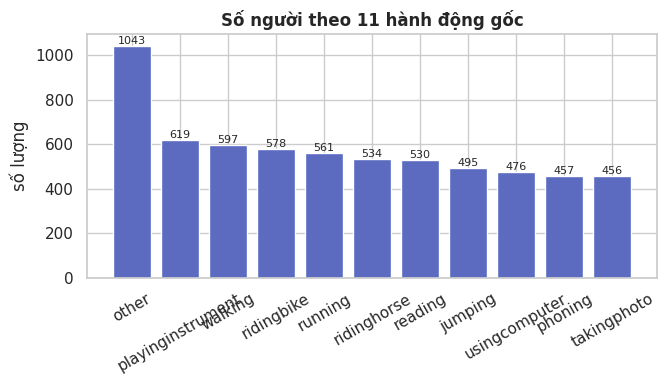

In [ ]:
print('Số ảnh                    :', df.image_id.nunique())
print('Số người có nhãn          :', len(df))
print('Số người có >1 hành động  :', (df['actions'].str.len() > 1).sum())
print('Số nhãn gốc               :', len(VOC_ACTIONS))
print('Split                     : dùng trainval (bộ test của VOC không công bố nhãn)')

# Đếm theo từng hành động (1 người nhiều hành động thì được đếm ở nhiều cột)
tung_hanh_dong = df.explode('actions')['actions']
display(bang_dem(tung_hanh_dong, 'hành động gốc'))
ve_cot(tung_hanh_dong, 'Số người theo 11 hành động gốc', xoay=30)

           width      height
min   164.000000  120.000000
mean  457.487358  397.475153
max   500.000000  500.000000


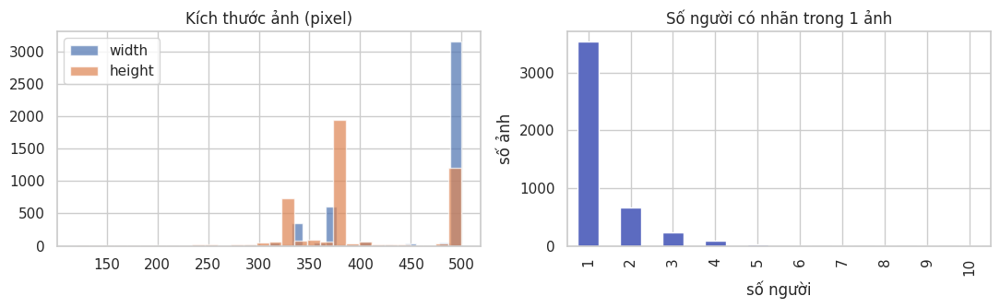

In [ ]:
# Kích thước ảnh và số người trong mỗi ảnh
anh = df.drop_duplicates('image_id')
print(anh[['width', 'height']].describe().loc[['min', 'mean', 'max']])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(anh['width'], bins=30, alpha=.7, label='width'); axes[0].hist(anh['height'], bins=30, alpha=.7, label='height')
axes[0].set_title('Kích thước ảnh (pixel)'); axes[0].legend()
df.groupby('image_id').size().value_counts().sort_index().plot.bar(ax=axes[1], color='#5C6BC0')
axes[1].set_title('Số người có nhãn trong 1 ảnh'); axes[1].set_xlabel('số người'); axes[1].set_ylabel('số ảnh')
plt.tight_layout(); plt.show()

**Xem ảnh mẫu:** mỗi hành động 3 người (khung xanh là bbox của người mang nhãn đó).

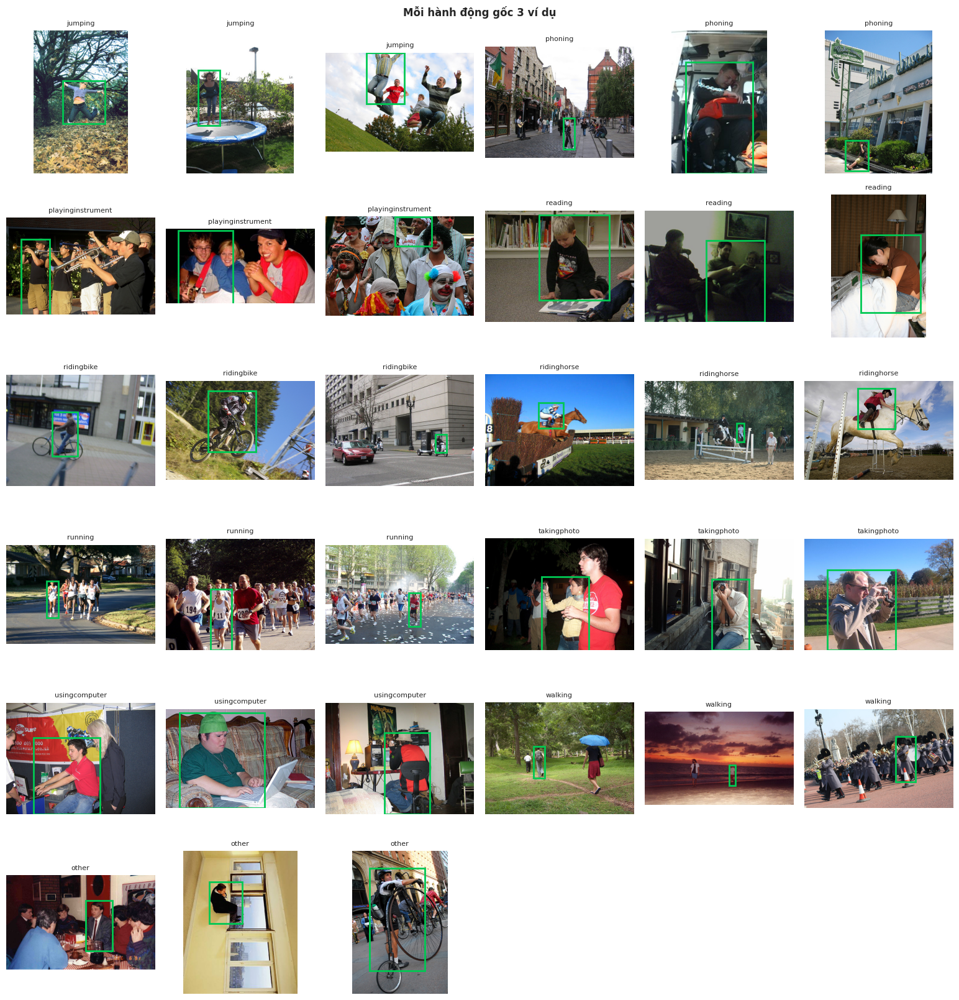

In [ ]:
items = []
for act in VOC_ACTIONS:
    sub = df[df['actions'].apply(lambda a: act in a)]
    for r in sub.sample(min(3, len(sub)), random_state=42).itertuples():
        items.append({'img': r.image_path, 'title': act, 'boxes': [(*r.bbox, '#00C853', '')]})
show_grid(items, 'Mỗi hành động gốc 3 ví dụ', ncols=6)

📝 **Nhận xét của bạn:** *(ví dụ: người nhỏ, nhiều người trong ảnh, hành động khó nhìn…)*

📌 **Kết luận phần 1**
- Nhãn gắn với **từng người** (có bbox), nên khi training có thể **cắt (crop) người** ra để phân loại.
- Nhiều ảnh có hơn 1 người; một số người có hơn 1 hành động.
- Ảnh cỡ ~500×375, lớn hơn nhiều so với Stanford40 (128×128).

## Phần 2: Map sang 6 nhãn đích

**Cách làm:** một **bảng tra** (`dict`) *hành động gốc → nhãn đích*. Nếu 1 người có nhiều hành động, dùng **priority rule** (quy tắc ưu tiên): chọn nhãn đứng trước trong
`take_on_phone > work_on_computer > eat/drink > ride > hold > unknown`.

In [ ]:
MAPPING = {
    'phoning': 'take_on_phone',
    'usingcomputer': 'work_on_computer',
    'ridingbike': 'ride', 'ridinghorse': 'ride',
    'playinginstrument': 'hold', 'takingphoto': 'hold', 'reading': 'hold',
    'jumping': 'unknown', 'running': 'unknown', 'walking': 'unknown', 'other': 'unknown',
}

def map_nguoi(actions):
    """Map danh sách hành động của 1 người sang 1 nhãn đích theo priority rule."""
    cac_nhan = [MAPPING[a] for a in actions]
    return min(cac_nhan, key=PRIORITY.index)

df['target_label'] = df['actions'].apply(map_nguoi)
pd.DataFrame({'hành động gốc': list(MAPPING), 'nhãn đích': list(MAPPING.values())})

,hành động gốc,nhãn đích
0,phoning,take_on_phone
1,usingcomputer,work_on_computer
2,ridingbike,ride
3,ridinghorse,ride
4,playinginstrument,hold
5,takingphoto,hold
6,reading,hold
7,jumping,unknown
8,running,unknown
9,walking,unknown


,nhãn đích,số lượng,tỷ lệ %
0,unknown,2648,42.2
1,hold,1594,25.4
2,ride,1106,17.6
3,work_on_computer,473,7.5
4,take_on_phone,457,7.3


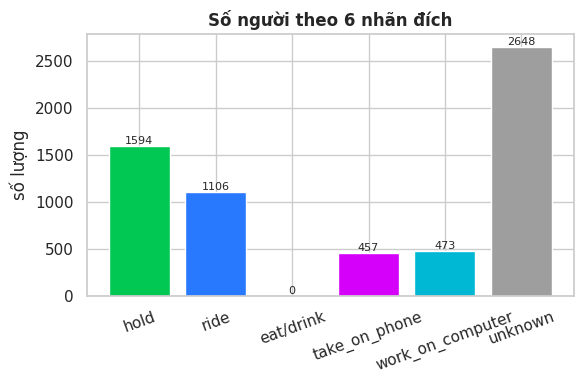

In [ ]:
display(bang_dem(df['target_label'], 'nhãn đích'))
ve_cot(df['target_label'], 'Số người theo 6 nhãn đích', theo_6_lop=True, xoay=20)

**5 người ngẫu nhiên cho mỗi nhãn đích** (khung màu là người được xét, chữ là nhãn gốc):

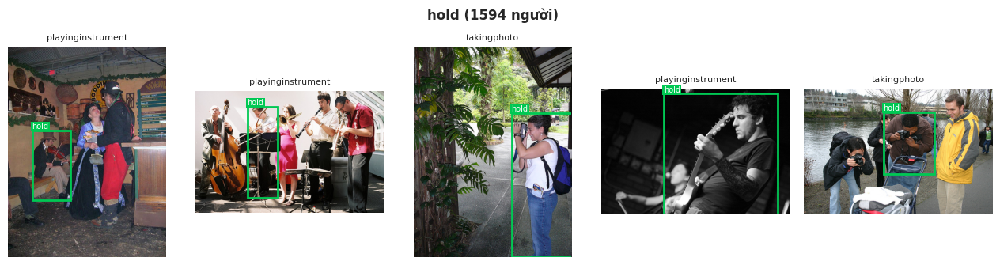

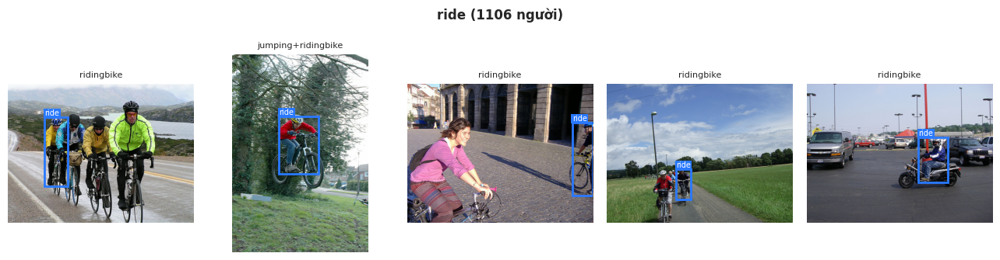

ℹ️ eat/drink: 0 người, PASCAL VOC Action không có hành động này


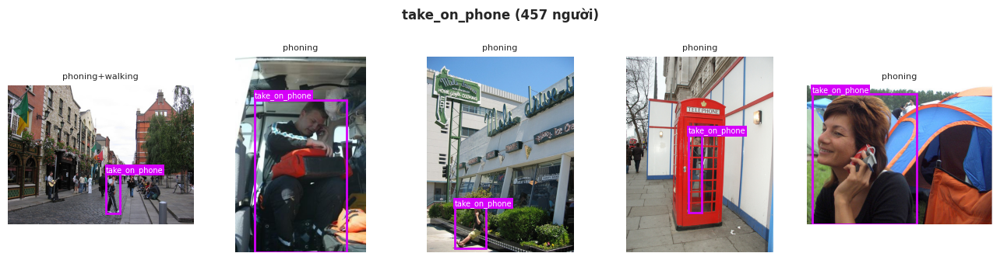

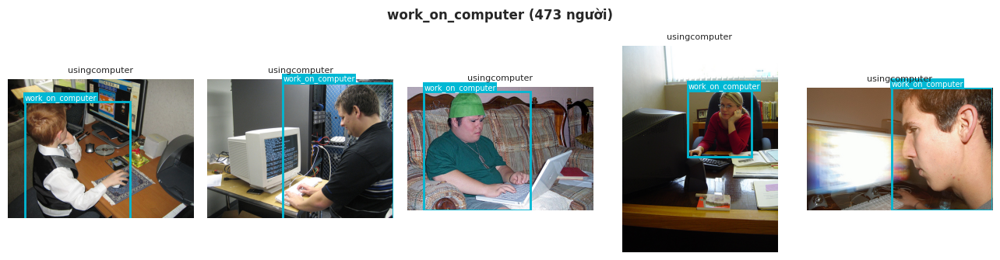

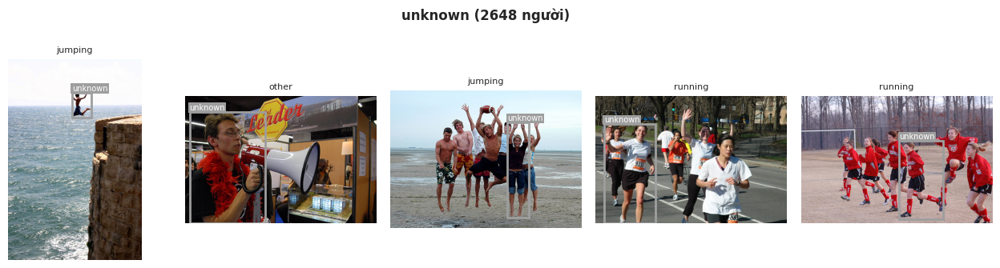

In [ ]:
for cls in TARGET_CLASSES:
    sub = df[df['target_label'] == cls]
    if len(sub) == 0:
        print(f'ℹ️ {cls}: 0 người, PASCAL VOC Action không có hành động này'); continue
    rows = sub.sample(min(5, len(sub)), random_state=42)
    show_grid([{'img': r.image_path, 'title': r.original_label, 'boxes': [(*r.bbox, CLASS_COLORS[cls], cls)]}
               for r in rows.itertuples()], f'{cls} ({len(sub)} người)', ncols=5)

In [ ]:
# vật thể + hành động của các nhãn gốc đang map vào hold (dùng cho phần 4)
HOLD_INFO = {'reading': ('book', 'read'), 'playinginstrument': ('instrument', 'play'), 'takingphoto': ('camera', 'take_photo')}

def hold_info(actions):
    for a in actions:
        if a in HOLD_INFO:
            return HOLD_INFO[a]
    return ('', '')

df['hold_object'] = df['actions'].apply(lambda a: hold_info(a)[0])
df['hold_verb'] = df['actions'].apply(lambda a: hold_info(a)[1])

df_labels = pd.DataFrame({
    'dataset': 'pascal_voc',
    'image': df['image_path'],
    'person_bbox': df['bbox'].apply(lambda b: ','.join(map(str, b))),   # x1,y1,x2,y2
    'object_bbox': '',
    'original_label': df['original_label'],
    'target_label': df['target_label'],
    'hold_object': df['hold_object'],
    'hold_verb': df['hold_verb'],
})
print('Đã tạo df_labels:', df_labels.shape, '(mỗi dòng = 1 người)')

Đã tạo df_labels: (6278, 8) (mỗi dòng = 1 người)


📌 **Kết luận phần 2**
- `eat/drink` có **0 mẫu**: VOC Action không có hành động ăn uống.
- `unknown` chủ yếu là đi bộ, chạy, nhảy (không cầm vật).
- Mỗi dòng trong file nhãn là **1 người + bbox**, khác Stanford40 (1 dòng = 1 ảnh).

## Phần 3: Những chỗ map đáng nghi

**Cách đọc:** mỗi mục có *lý do nghi ngờ*, *số người bị ảnh hưởng*, và *6 ảnh* để kiểm tra (khung là người đang xét). Xem xong, trả lời câu hỏi **Giữ / Bỏ / Đổi lớp?**

🔎 Đọc sách → hold  |  530 người  |  đang map sang: {'hold': 527, 'take_on_phone': 2, 'ride': 1}
   Lý do nghi ngờ: Stanford40 lại map reading → unknown. Hai bộ KHÔNG nhất quán, cần chọn 1 cách.


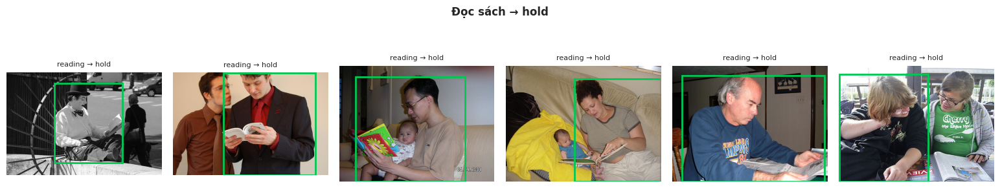

   ❓ Giữ / Bỏ / Đổi lớp?
🔎 Chụp ảnh → hold  |  456 người  |  đang map sang: {'hold': 455, 'ride': 1}
   Lý do nghi ngờ: Có người chụp bằng điện thoại, trông giống take_on_phone.


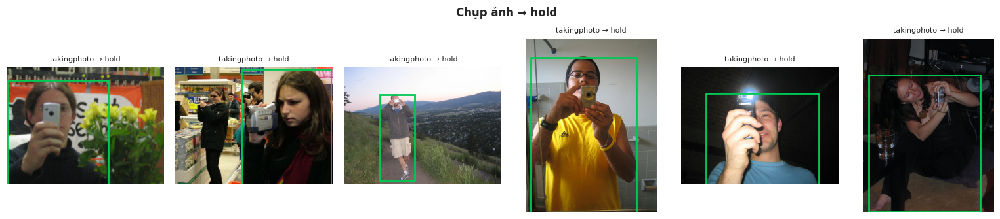

   ❓ Giữ / Bỏ / Đổi lớp?
🔎 Chơi nhạc cụ → hold  |  619 người  |  đang map sang: {'hold': 617, 'ride': 1, 'work_on_computer': 1}
   Lý do nghi ngờ: Đánh đàn/thổi kèn: là CHƠI, tư thế khác xa cầm vật.


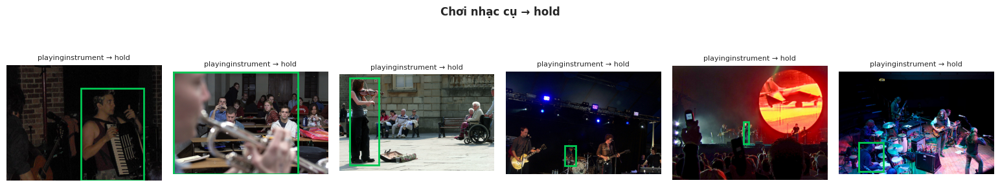

   ❓ Giữ / Bỏ / Đổi lớp?
🔎 "other" → unknown  |  1043 người  |  đang map sang: {'unknown': 1043}
   Lý do nghi ngờ: "other" là mọi hành động còn lại, có thể đang ăn, uống, cầm vật… nhưng đều thành unknown.


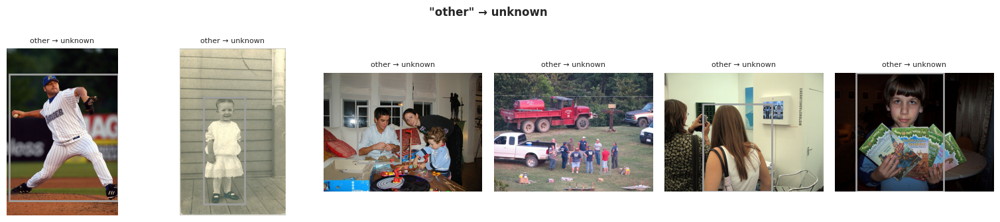

   ❓ Giữ / Bỏ / Đổi lớp?
🔎 Người có nhiều hành động cùng lúc  |  68 người  |  đang map sang: {'ride': 28, 'take_on_phone': 24, 'hold': 15, 'work_on_computer': 1}
   Lý do nghi ngờ: Priority rule chỉ giữ 1 nhãn, cần xem nhãn được chọn có hợp lý không.


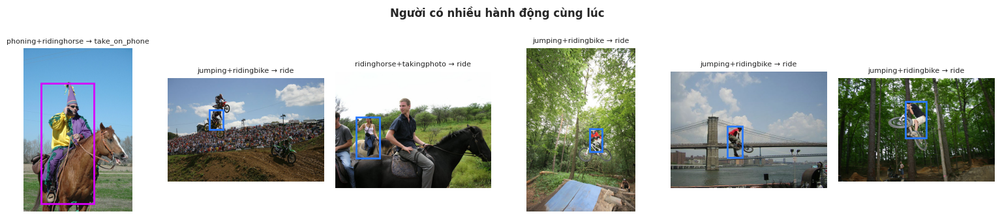

   ❓ Giữ / Bỏ / Đổi lớp?


In [ ]:
NGHI_NGO = [
    {'ten': 'Đọc sách → hold', 'dieu_kien': lambda a: 'reading' in a,
     'ly_do': 'Stanford40 lại map reading → unknown. Hai bộ KHÔNG nhất quán, cần chọn 1 cách.'},
    {'ten': 'Chụp ảnh → hold', 'dieu_kien': lambda a: 'takingphoto' in a,
     'ly_do': 'Có người chụp bằng điện thoại, trông giống take_on_phone.'},
    {'ten': 'Chơi nhạc cụ → hold', 'dieu_kien': lambda a: 'playinginstrument' in a,
     'ly_do': 'Đánh đàn/thổi kèn: là CHƠI, tư thế khác xa cầm vật.'},
    {'ten': '"other" → unknown', 'dieu_kien': lambda a: a == ['other'],
     'ly_do': '"other" là mọi hành động còn lại, có thể đang ăn, uống, cầm vật… nhưng đều thành unknown.'},
    {'ten': 'Người có nhiều hành động cùng lúc', 'dieu_kien': lambda a: len(a) > 1,
     'ly_do': 'Priority rule chỉ giữ 1 nhãn, cần xem nhãn được chọn có hợp lý không.'},
]

for ng in NGHI_NGO:
    sub = df[df['actions'].apply(ng['dieu_kien'])]
    print('=' * 100)
    print(f"🔎 {ng['ten']}  |  {len(sub)} người  |  đang map sang: {sub['target_label'].value_counts().to_dict()}")
    print(f"   Lý do nghi ngờ: {ng['ly_do']}")
    rows = sub.sample(min(6, len(sub)), random_state=1)
    show_grid([{'img': r.image_path, 'title': f'{r.original_label} → {r.target_label}',
                'boxes': [(*r.bbox, CLASS_COLORS[r.target_label], '')]} for r in rows.itertuples()], ng['ten'])
    print('   ❓ Giữ / Bỏ / Đổi lớp?')

**Nghi ngờ: 1 ảnh có nhiều người mang nhãn đích KHÁC nhau.** Nếu training theo **cả ảnh** (như Stanford40), ảnh này không biết gán nhãn gì. Nếu training theo **từng người (crop bbox)** thì không sao.

175 / 4588 ảnh có ≥2 nhãn đích khác nhau


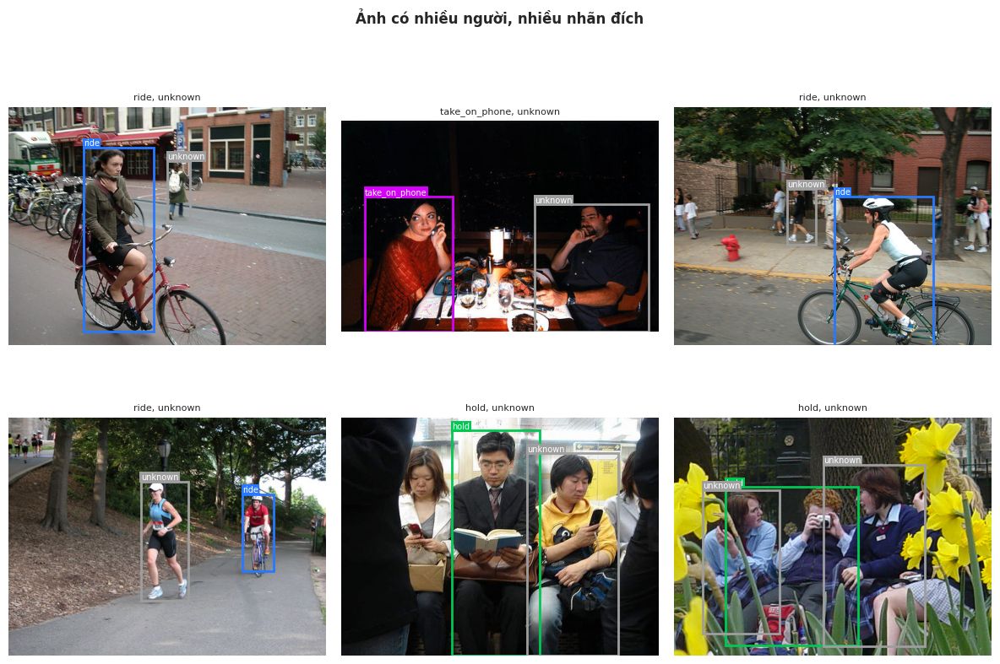

In [ ]:
nhan_moi_anh = df.groupby('image_id')['target_label'].nunique()
anh_nhieu_nhan = nhan_moi_anh[nhan_moi_anh > 1].index
print(f'{len(anh_nhieu_nhan)} / {df.image_id.nunique()} ảnh có ≥2 nhãn đích khác nhau')

items = []
for img_id in pd.Series(anh_nhieu_nhan).sample(min(6, len(anh_nhieu_nhan)), random_state=0):
    nguoi = df[df.image_id == img_id]
    items.append({'img': nguoi.image_path.iloc[0], 'title': ', '.join(sorted(set(nguoi.target_label))),
                  'boxes': [(*r.bbox, CLASS_COLORS[r.target_label], r.target_label) for r in nguoi.itertuples()]})
show_grid(items, 'Ảnh có nhiều người, nhiều nhãn đích', ncols=3, size=4)

**Nghi ngờ: người quá nhỏ.** Khi crop người ra rồi phóng to lên 224×224, người quá nhỏ sẽ rất mờ. Ta đếm số người có bbox nhỏ hơn 50 pixel (chiều cao).

148 người (2.4%) có chiều cao bbox < 50 pixel


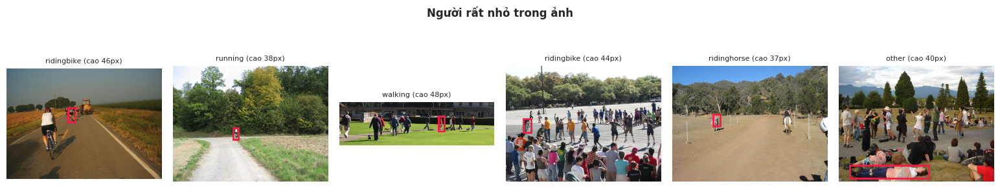

In [ ]:
df['box_h'] = df['bbox'].apply(lambda b: b[3] - b[1])
nho = df[df['box_h'] < 50]
print(f'{len(nho)} người ({len(nho) / len(df) * 100:.1f}%) có chiều cao bbox < 50 pixel')
show_grid([{'img': r.image_path, 'title': f'{r.original_label} (cao {r.box_h}px)', 'boxes': [(*r.bbox, '#FF1744', '')]}
           for r in nho.sample(min(6, len(nho)), random_state=0).itertuples()], 'Người rất nhỏ trong ảnh')

📌 **Kết luận phần 3**: các quyết định cần chốt:
- `reading`: thống nhất giữa VOC và Stanford40 (cùng `hold` hoặc cùng `unknown`).
- `takingphoto`: nếu chụp bằng điện thoại thì có nên là `take_on_phone`?
- `other`: là nhóm "linh tinh", có thể chứa người đang ăn/cầm vật, nên **cân nhắc bỏ** khỏi `unknown`.
- Nên training theo **từng người (crop bbox)** để tránh ảnh nhiều nhãn; lọc bỏ người quá nhỏ.

## Phần 4: Lớp `hold` quá rộng: dẫn chứng và đề xuất

### 4.1 Dẫn chứng
**Cách đọc:** nhiều kiểu (vật khác, tư thế khác) mà chung 1 nhãn thì model phải học khái niệm "cầm bất cứ thứ gì", rất khó.

In [ ]:
hold_df = df_labels[df_labels['target_label'] == 'hold']
if len(hold_df) == 0:
    print('Lớp hold không có mẫu nào trong bộ này.')
else:
    comp = bang_dem(hold_df['hold_object'].astype(str) + '  |  ' + hold_df['hold_verb'].astype(str),
                    'vật | hành động')
    print(f'Lớp hold có {len(hold_df)} mẫu, gồm {len(comp)} kiểu (vật | hành động) khác nhau')
    top5 = comp['số lượng'].head(5).sum() / len(hold_df) * 100
    print(f'Top-5 kiểu chiếm {top5:.1f}% lớp hold '
          '(càng thấp = càng phân tán = càng khó học)')
    counts = df_labels['target_label'].value_counts()
    nho_nhat = counts[counts > 0].min()
    print(f'hold gấp {counts["hold"] / nho_nhat:.1f} lần lớp nhỏ nhất ({counts.idxmin()}: {nho_nhat})')
    display(comp.head(20))

Lớp hold có 1594 mẫu, gồm 3 kiểu (vật | hành động) khác nhau
Top-5 kiểu chiếm 100.0% lớp hold (càng thấp = càng phân tán = càng khó học)
hold gấp 3.5 lần lớp nhỏ nhất (take_on_phone: 457)


,vật | hành động,số lượng,tỷ lệ %
0,instrument | play,617,38.7
1,book | read,522,32.7
2,camera | take_photo,455,28.5


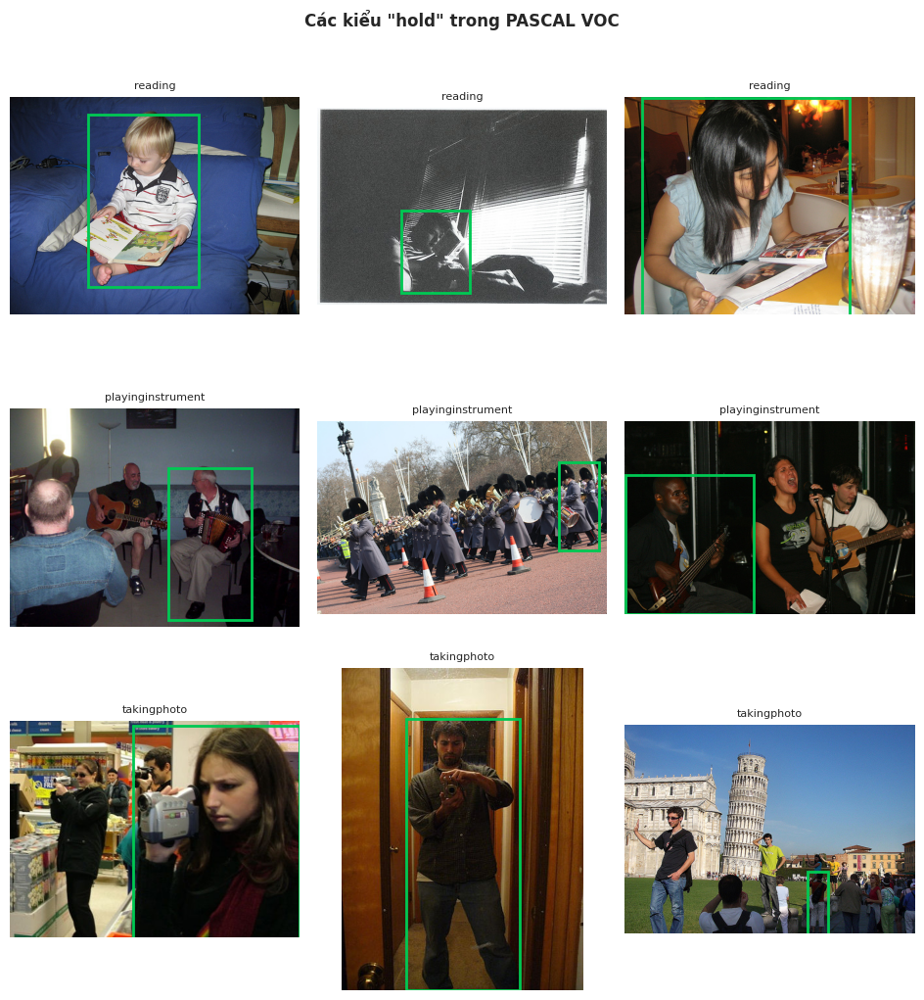

In [ ]:
items = []
for act in HOLD_INFO:
    sub = df[df['actions'].apply(lambda a: act in a) & (df['target_label'] == 'hold')]
    for r in sub.sample(min(3, len(sub)), random_state=3).itertuples():
        items.append({'img': r.image_path, 'title': act, 'boxes': [(*r.bbox, CLASS_COLORS['hold'], '')]})
show_grid(items, 'Các kiểu "hold" trong PASCAL VOC', ncols=3, size=3.2)

### 4.2 Ba phương án giới hạn `hold`

| Phương án | Ý tưởng | Đổi nhãn? |
|---|---|---|
| **A. Theo vật thể** | Chỉ giữ `hold` khi vật là **đồ nhỏ cầm tay** (danh sách `HOLD_OBJECTS` bên dưới). Nhạc cụ, ván trượt, vợt, gậy, diều… chuyển sang `unknown` | Có |
| **B. Theo động từ** | Chỉ giữ `hold` khi hành động đúng là **cầm/mang** (`hold`, `carry`). Các hành động "chơi", "chụp", "vung"… chuyển sang `unknown` | Có |
| **C. Cắt số lượng** | Giữ nguyên định nghĩa, chỉ **bớt mẫu `hold`** khi training (tối đa `k` lần lớp nhỏ nhất) | Không, chỉ đổi cách lấy mẫu |

👉 **Khuyến nghị mặc định: A + B**, tức `hold` = *cầm hoặc mang một vật nhỏ bằng tay*. Định nghĩa hẹp và rõ thì model dễ học hơn. **C** để dành cho lúc training (dùng sampler), không dùng để sửa nhãn.

Bạn đổi phương án bằng biến `HOLD_POLICY` ở cell dưới: `None`, `'A'`, `'B'`, `'A+B'`.

In [ ]:
HOLD_POLICY = 'A+B'   # 👈 đổi ở đây: None | 'A' | 'B' | 'A+B'

# Đồ vật nhỏ cầm tay (tên theo kiểu COCO, dùng dấu gạch dưới)
HOLD_OBJECTS = {
    'cup', 'bottle', 'wine_glass', 'bowl', 'umbrella', 'handbag', 'backpack', 'suitcase', 'tie',
    'book', 'knife', 'fork', 'spoon', 'scissors', 'remote', 'toothbrush', 'hair_drier',
    'teddy_bear', 'vase', 'camera', 'clock', 'banana', 'apple', 'orange', 'sandwich',
    'hot_dog', 'pizza', 'donut', 'cake', 'carrot', 'broccoli',
}
HOLD_VERBS = {'hold', 'carry'}


def gioi_han_hold(row, policy=HOLD_POLICY):
    """Trả về nhãn mới sau khi áp phương án giới hạn hold cho 1 dòng."""
    lbl = row['target_label']
    if lbl != 'hold' or policy is None:
        return lbl
    obj = str(row.get('hold_object', '')).replace(' ', '_')
    verb = str(row.get('hold_verb', ''))
    if 'A' in policy and obj not in HOLD_OBJECTS:
        return 'unknown'
    if 'B' in policy and verb not in HOLD_VERBS:
        return 'unknown'
    return lbl


def so_sanh_phuong_an(df):
    """Bảng số mẫu 6 lớp: trước và sau từng phương án A, B, A+B, và C (k=3)."""
    out = pd.DataFrame(index=TARGET_CLASSES)
    out['hiện tại'] = df['target_label'].value_counts().reindex(TARGET_CLASSES, fill_value=0)
    for p in ['A', 'B', 'A+B']:
        out[p] = df.apply(lambda r: gioi_han_hold(r, p), axis=1).value_counts().reindex(TARGET_CLASSES, fill_value=0)
    nho_nhat = out['hiện tại'][out['hiện tại'] > 0].min()
    out['C (k=3)'] = out['hiện tại']
    out.loc['hold', 'C (k=3)'] = min(out.loc['hold', 'hiện tại'], 3 * nho_nhat)
    return out

,hiện tại,A,B,A+B,C (k=3)
hold,1594,977,0,0,1371
ride,1106,1106,1106,1106,1106
eat/drink,0,0,0,0,0
take_on_phone,457,457,457,457,457
work_on_computer,473,473,473,473,473
unknown,2648,3265,4242,4242,2648


Phương án A+B: 1594 người bị đẩy ra khỏi hold


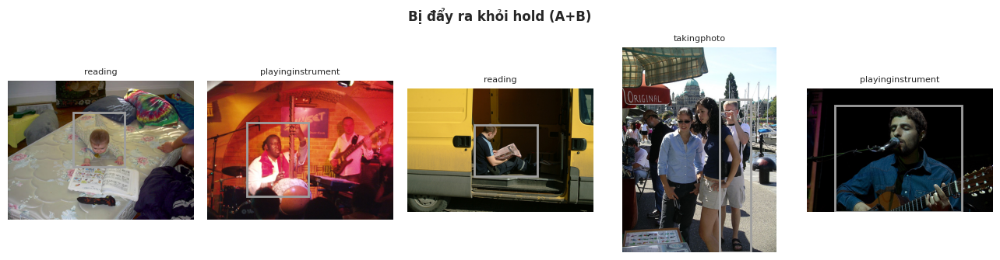

In [ ]:
display(so_sanh_phuong_an(df_labels))
df_labels['target_label_hold_limited'] = df_labels.apply(gioi_han_hold, axis=1)

bi_day = df_labels[(df_labels['target_label'] == 'hold') & (df_labels['target_label_hold_limited'] != 'hold')]
print(f'Phương án {HOLD_POLICY}: {len(bi_day)} người bị đẩy ra khỏi hold')
show_grid([{'img': r.image, 'title': r.original_label,
            'boxes': [(*map(int, r.person_bbox.split(',')), '#9E9E9E', '')]}
           for r in bi_day.sample(min(5, len(bi_day)), random_state=0).itertuples()],
          f'Bị đẩy ra khỏi hold ({HOLD_POLICY})', ncols=5)

In [ ]:
df_labels.to_csv('labels_6class_pascal_voc.csv', index=False)
print('💾 Đã lưu', os.path.abspath('labels_6class_pascal_voc.csv'), df_labels.shape)

💾 Đã lưu /content/pascal_voc/labels_6class_pascal_voc.csv (6278, 9)


📌 **Kết luận phần 4**
- `hold` trong VOC gồm 3 kiểu: **đọc sách**, **chơi nhạc cụ**, **chụp ảnh**. Không kiểu nào là "cầm" đơn thuần.
- Với **A** (theo vật thể): nhạc cụ bị loại, sách và máy ảnh ở lại. Với **B** (theo động từ): cả 3 đều bị loại, vì không có động từ `hold`/`carry`.
- Nghĩa là nếu định nghĩa `hold` chặt (A+B), **VOC không đóng góp mẫu `hold` nào**. Đây là dẫn chứng rõ rằng `hold` hiện tại đang "gom" các hành động khác vào.